<div id="task2">

  <h1>P2: EKF-Enhanced MPC for a DC Motor</h1>
  <h2>Implementation of the MPC controller without EKF</h2>

  <p>
    In this notebook, I design and evaluate a <strong>nonlinear Model Predictive Controller (MPC)</strong>
    for a DC motor system. In contrast to Task&nbsp;1, no state estimation is performed here.
    The controller is assumed to have direct access to the full system state
    <strong>x = [i<sub>a</sub>, &omega;]</strong>.
  </p>

  <p>
    This task serves as a <strong>noise-free baseline</strong> to evaluate the ideal closed-loop
    performance of the MPC when the prediction model is identical to the plant model.
    The results obtained here will later be compared with noisy and mismatched cases
    in Task&nbsp;3.
  </p>

  <h3>Objective</h3>
  <p>
    The objective of this task is to design a nonlinear MPC controller that regulates
    the angular velocity <strong>&omega;</strong> of the DC motor to multiple reference values,
    while explicitly enforcing physical constraints on the input and the system states.
  </p>

  <h3>System Model</h3>
  <p>
    The DC motor is described by a nonlinear continuous-time state-space model with
    the armature current <strong>i<sub>a</sub></strong> and the angular velocity
    <strong>&omega;</strong> as states, and the field current <strong>u</strong> as control input.
    For this task, the simulation is performed without process noise or measurement noise,
    and the prediction model matches the true plant exactly.
  </p>

  <h3>Methodology: Orthogonal Collocation on Finite Elements</h3>
  <p>
    The continuous-time system dynamics are discretized using
    <strong>orthogonal collocation on finite elements</strong> with Radau collocation points.
    This method approximates the state trajectory within each sampling interval using
    a polynomial and enforces the system dynamics at selected collocation points.
  </p>

  <ul>
    <li><strong>Accurate discretization:</strong> Nonlinear dynamics are represented with high fidelity.</li>
    <li><strong>All-at-once formulation:</strong> State trajectories and control inputs are optimized simultaneously.</li>
    <li><strong>Constraint handling:</strong> State and input constraints are enforced directly within the optimization.</li>
  </ul>

  <h3>MPC Formulation</h3>
  <p>
    A nonlinear set-point tracking MPC problem is solved at each sampling time.
    The cost function penalizes deviations of the angular velocity from the reference
    as well as large armature currents and excessive control effort.
  </p>

  <p>
    The following constraints are enforced throughout the prediction horizon:
  </p>

  <ul>
    <li><strong>Input constraint:</strong> &minus;5 &le; u &le; 5</li>
    <li><strong>Current constraint:</strong> &minus;10 &le; i<sub>a</sub> &le; 10</li>
    <li><strong>Speed constraint:</strong> &minus;200 &le; &omega; &le; 35</li>
  </ul>

  <h3>Closed-Loop Simulation Setup</h3>
  <p>
    The MPC is applied in a receding-horizon fashion. At each sampling instant,
    the optimization problem is solved, the first control input is applied to the plant,
    and the system is simulated forward by one sampling period.
  </p>

  <p>
    The controller is tested using multiple reference values for the angular velocity:
  </p>

  <ul>
    <li>&omega;<sub>sp</sub> = &minus;36 rad/s</li>
    <li>&omega;<sub>sp</sub> = &minus;175 rad/s</li>
    <li>&omega;<sub>sp</sub> = 30 rad/s</li>
  </ul>

  <h3>Results</h3>
  <p>
    The simulation results demonstrate that the MPC is able to track all reference
    values smoothly while respecting the imposed state and input constraints.
    Since the system is noise-free and the model is perfectly known, the controller
    achieves stable and accurate tracking behavior.
  </p>

  <h3>Discussion</h3>
  <p>
    This task highlights the ideal performance of nonlinear MPC under perfect
    modeling conditions. The obtained results serve as a benchmark for later
    investigations in which process noise, measurement noise, and model-plant
    mismatch are introduced together with state estimation using an EKF.
  </p>

  <hr>

</div>


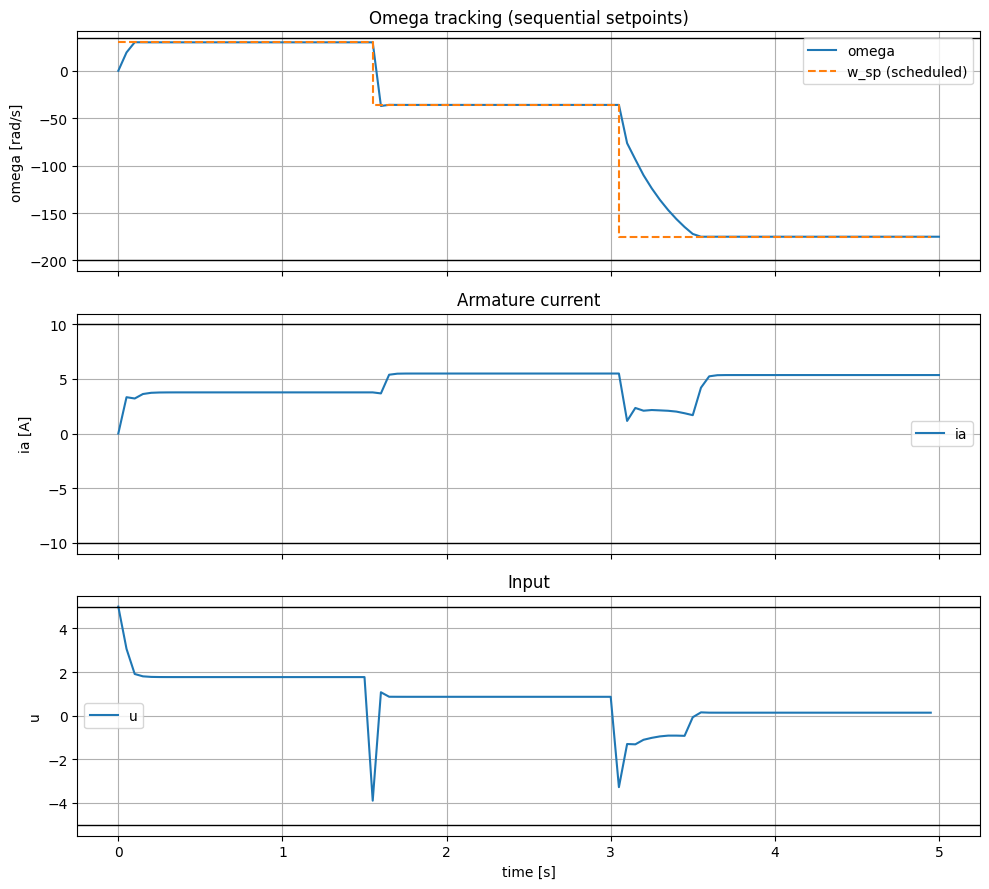

In [4]:
# =========================
# Imports
# =========================
from casadi import *
from casadi.tools import *
import numpy as np
import matplotlib.pyplot as plt

# =========================
# Parameters (from task sheet)
# =========================
Ra = 12.345
km = 0.253
B = 0.00732
tl = 1.47
La = 0.314
J = 0.00441
ua = 60.0
dt = 0.05

nx = 2  # [ia, omega]
nu = 1  # [u]

# MPC settings
N = 20  # horizon
K = 2  # collocation degree (2 is a good start)
K1 = K + 1

# Constraints (task sheet)
u_min, u_max = -5.0, 5.0
ia_min, ia_max = -10.0, 10.0
w_min, w_max = -200.0, 35.0

# Cost weights (tune if needed)
Qw = 50.0  # omega tracking
Qi = 0.1  # keep ia moderate
Ru = 0.01  # input effort

# =========================
# Continuous-time model xdot = f(x,u)
# =========================
x = SX.sym("x", nx, 1)  # [ia, omega]
u = SX.sym("u", nu, 1)  # field current

ia = x[0]
om = x[1]

# From project statement (noise-free here) [file:2]
xdot = vertcat(
    -(Ra / La) * ia - (km / La) * om * u[0] + (ua / La),
    -(B / J) * om + (km / J) * ia * u[0] - (tl / J)
)

system = Function("sys", [x, u], [xdot])

# =========================
# Plant simulator (IDAS) - like tutorial uses for simulation [file:1]
# =========================
ode = {"x": x, "p": u, "ode": system(x, u)}
F = integrator("F", "idas", ode, {"tf": dt})


def simulate_step(xk, uk):
    # xk: DM(nx), uk: DM(nu)
    out = F(x0=xk, p=uk)
    return out["xf"]


# =========================
# Orthogonal collocation coefficients (Radau) [file:1]
# =========================
tau_col = collocation_points(K, "radau")  # excludes 0
tau_col = [0.0] + tau_col  # include 0

tau = SX.sym("tau")


def L(j):
    lj = 1
    for r in range(K1):
        if r != j:
            lj *= (tau - tau_col[r]) / (tau_col[j] - tau_col[r])
    return lj


A = np.zeros((K1, K1))
D = np.zeros((K1, 1))
for j in range(K1):
    dLj = Function(f"dLj{j}", [tau], [jacobian(L(j), tau)])
    Lj = Function(f"Lj{j}", [tau], [L(j)])
    for k in range(K1):
        A[j, k] = float(dLj(tau_col[k]))
    D[j] = float(Lj(1.0))

# =========================
# NMPC NLP (structured decision variables) [file:1]
# =========================
opt = struct_symSX([
    entry("x", shape=(nx,), repeat=[N + 1, K1]),  # x[i,j]
    entry("u", shape=(nu,), repeat=[N])  # u[i]
])
w_opt = opt.cat

# Parameters to the NLP: initial state and omega setpoint
x_init = SX.sym("x_init", nx)
w_sp = SX.sym("w_sp")  # scalar setpoint
p = vertcat(x_init, w_sp)


# Cost definitions (tracking omega)
def stage_cost(xij, ui):
    ia_ = xij[0]
    om_ = xij[1]
    return Qw * (om_ - w_sp) ** 2 + Qi * (ia_ - 0.0) ** 2 + Ru * (ui[0] ** 2)


def terminal_cost(xN0):
    ia_ = xN0[0]
    om_ = xN0[1]
    return Qw * (om_ - w_sp) ** 2 + Qi * (ia_ - 0.0) ** 2


Jcost = 0
g = []
lbg = []
ubg = []

# Initial condition constraint: x[0,0] = x_init [file:1]
g.append(opt["x", 0, 0] - x_init)
lbg += [0.0] * nx
ubg += [0.0] * nx

# Loop over finite elements
for i in range(N):
    ui = opt["u", i]

    # stage cost evaluated at j=0 (like tutorial example) [file:1]
    Jcost += stage_cost(opt["x", i, 0], ui)

    # Collocation constraints for k = 1..K [file:1]
    for k in range(1, K1):
        x_ik = opt["x", i, k]
        fk = system(x_ik, ui)

        # sum_j A[j,k] * x[i,j] = dt * f(x[i,k], u[i])
        gk = 0
        for j in range(K1):
            gk += A[j, k] * opt["x", i, j]
        g.append(gk - dt * fk)
        lbg += [0.0] * nx
        ubg += [0.0] * nx

    # Continuity: x[i+1,0] = sum_j D[j] * x[i,j] [file:1]
    x_end = 0
    for j in range(K1):
        x_end += D[j] * opt["x", i, j]
    g.append(opt["x", i + 1, 0] - x_end)
    lbg += [0.0] * nx
    ubg += [0.0] * nx

# Terminal cost on x[N,0]
Jcost += terminal_cost(opt["x", N, 0])

g = vertcat(*g)

# =========================
# Bounds (constraints) [file:2]
# =========================
lbw = opt(0)
ubw = opt(0)

# State bounds at all collocation points
for i in range(N + 1):
    for j in range(K1):
        lbw["x", i, j] = [ia_min, w_min]
        ubw["x", i, j] = [ia_max, w_max]

# Input bounds
for i in range(N):
    lbw["u", i] = [u_min]
    ubw["u", i] = [u_max]

# =========================
# Create solver
# =========================
nlp = {"x": w_opt, "f": Jcost, "g": g, "p": p}
opts = {
    "ipopt.print_level": 0,
    "print_time": 0,
    "ipopt.max_iter": 300,
}
solver = nlpsol("solver", "ipopt", nlp, opts)


# =========================
# Helper: initial guess (important for IPOPT stability) [file:1]
# =========================
def make_initial_guess(xk):
    w0 = opt(0)
    for i in range(N + 1):
        for j in range(K1):
            w0["x", i, j] = xk
    for i in range(N):
        w0["u", i] = [0.0]
    return w0


# =========================
# Closed-loop simulation for one setpoint
# =========================
def run_closed_loop_sequential(setpoints_seq, x0, n_steps=300, tol=2.0, hold_steps=10):
    """
    Sequential setpoint tracking:
    start at setpoints_seq[0], switch to next when |omega-wsp|<tol for hold_steps consecutive steps.
    """
    xk = DM(x0).reshape((nx, 1))

    X_hist = [np.array(xk.full()).reshape(-1)]
    U_hist = []
    W_hist = []

    w0 = make_initial_guess(xk)

    sp_idx = 0
    wsp = float(setpoints_seq[sp_idx])
    in_band_count = 0

    for t in range(n_steps):
        # current setpoint as parameter
        pk = vertcat(xk, wsp)

        sol = solver(x0=w0, lbx=lbw, ubx=ubw, lbg=lbg, ubg=ubg, p=pk)

        st = solver.stats()
        if not st["success"]:
            raise RuntimeError(f"NLP failed at step {t}: {st}")

        opt_sol = opt(sol["x"])
        uk = opt_sol["u", 0]

        # simulate plant
        xk = simulate_step(xk, uk)

        # log
        om_now = float(xk[1])
        X_hist.append(np.array(xk.full()).reshape(-1))
        U_hist.append(np.array(uk.full()).reshape(-1))
        W_hist.append(wsp)

        # switching logic (after applying control)
        if abs(om_now - wsp) < tol:
            in_band_count += 1
        else:
            in_band_count = 0

        if (in_band_count >= hold_steps) and (sp_idx < len(setpoints_seq) - 1):
            sp_idx += 1
            wsp = float(setpoints_seq[sp_idx])
            in_band_count = 0  # reset counter after switching

        # warm start
        w0 = make_initial_guess(xk)

    return np.array(X_hist), np.array(U_hist), np.array(W_hist)



# =========================
# Run and plot for all required setpoints [file:2]
# =========================
setpoints_seq = [30, -36,-175]
x0 = [0.0, 0.0]

X_hist, U_hist, W_hist = run_closed_loop_sequential(
    setpoints_seq, x0, n_steps=100, tol=2.0, hold_steps=30
)

tX = np.arange(X_hist.shape[0]) * dt
tU = np.arange(U_hist.shape[0]) * dt

fig, axs = plt.subplots(3, 1, figsize=(10, 9), sharex=True)

axs[0].plot(tX, X_hist[:, 1], label="omega")
axs[0].step(tU, W_hist, where="post", linestyle="--", label="w_sp (scheduled)")
axs[0].axhline(w_min, color="k", linewidth=1)
axs[0].axhline(w_max, color="k", linewidth=1)
axs[0].set_ylabel("omega [rad/s]")
axs[0].set_title("Omega tracking (sequential setpoints)")
axs[0].grid(True)
axs[0].legend()

axs[1].plot(tX, X_hist[:, 0], label="ia")
axs[1].axhline(ia_min, color="k", linewidth=1)
axs[1].axhline(ia_max, color="k", linewidth=1)
axs[1].set_ylabel("ia [A]")
axs[1].set_title("Armature current")
axs[1].grid(True)
axs[1].legend()

axs[2].plot(tU, U_hist[:, 0], label="u")
axs[2].axhline(u_min, color="k", linewidth=1)
axs[2].axhline(u_max, color="k", linewidth=1)
axs[2].set_ylabel("u")
axs[2].set_xlabel("time [s]")
axs[2].set_title("Input")
axs[2].grid(True)
axs[2].legend()

plt.tight_layout()
plt.show()

<h2>Expanding the Performance Evaluation</h2>
<p>We have successfully verified the controller's performance using our initial set of reference values ($\omega_{set-point} \in \{-36, -175, 30\}$). These tests gave us a solid baseline, showing that the system is stable and capable of reaching specific targets.</p>
<p>However, to ensure the controller is truly robust, we cannot rely on just three data points. We need to subject the system to a broader range of operating conditions. By testing with a wider variety of multiple reference values, we can verify that the controller behaves consistently across the entire operating range, not just at the convenient points we picked first.</p>
<p>In this next phase, we will sweep through different target velocities—including edge cases and varying step sizes—to confirm that our MPC design maintains its accuracy and stability under diverse scenarios.</p>

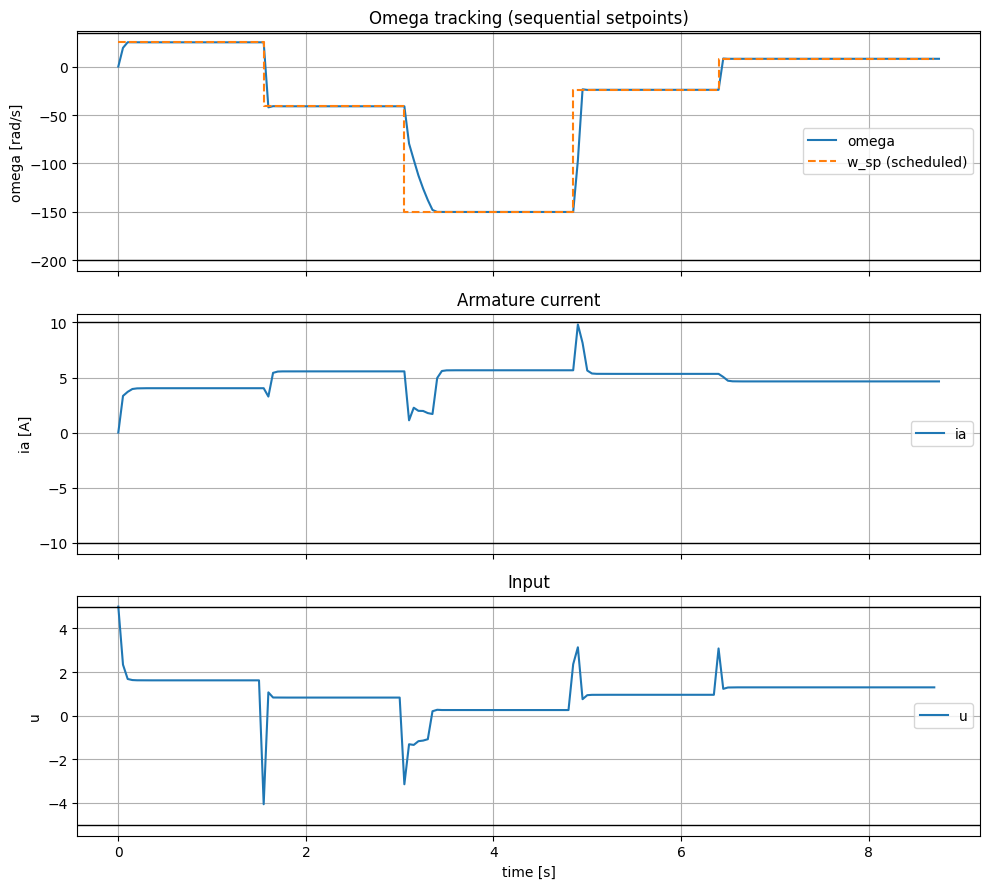

In [11]:
# =========================
# Imports
# =========================
from casadi import *
from casadi.tools import *
import numpy as np
import matplotlib.pyplot as plt

# =========================
# Parameters (from task sheet)
# =========================
Ra = 12.345
km = 0.253
B = 0.00732
tl = 1.47
La = 0.314
J = 0.00441
ua = 60.0
dt = 0.05

nx = 2  # [ia, omega]
nu = 1  # [u]

# MPC settings
N = 20  # horizon
K = 2  # collocation degree (2 is a good start)
K1 = K + 1

# Constraints (task sheet)
u_min, u_max = -5.0, 5.0
ia_min, ia_max = -10.0, 10.0
w_min, w_max = -200.0, 35.0

# Cost weights (tune if needed)
Qw = 50.0  # omega tracking
Qi = 0.1  # keep ia moderate
Ru = 0.01  # input effort

# =========================
# Continuous-time model xdot = f(x,u)
# =========================
x = SX.sym("x", nx, 1)  # [ia, omega]
u = SX.sym("u", nu, 1)  # field current

ia = x[0]
om = x[1]

# From project statement (noise-free here) [file:2]
xdot = vertcat(
    -(Ra / La) * ia - (km / La) * om * u[0] + (ua / La),
    -(B / J) * om + (km / J) * ia * u[0] - (tl / J)
)

system = Function("sys", [x, u], [xdot])

# =========================
# Plant simulator (IDAS) - like tutorial uses for simulation [file:1]
# =========================
ode = {"x": x, "p": u, "ode": system(x, u)}
F = integrator("F", "idas", ode, {"tf": dt})


def simulate_step(xk, uk):
    # xk: DM(nx), uk: DM(nu)
    out = F(x0=xk, p=uk)
    return out["xf"]


# =========================
# Orthogonal collocation coefficients (Radau) [file:1]
# =========================
tau_col = collocation_points(K, "radau")  # excludes 0
tau_col = [0.0] + tau_col  # include 0

tau = SX.sym("tau")


def L(j):
    lj = 1
    for r in range(K1):
        if r != j:
            lj *= (tau - tau_col[r]) / (tau_col[j] - tau_col[r])
    return lj


A = np.zeros((K1, K1))
D = np.zeros((K1, 1))
for j in range(K1):
    dLj = Function(f"dLj{j}", [tau], [jacobian(L(j), tau)])
    Lj = Function(f"Lj{j}", [tau], [L(j)])
    for k in range(K1):
        A[j, k] = float(dLj(tau_col[k]))
    D[j] = float(Lj(1.0))

# =========================
# NMPC NLP (structured decision variables) [file:1]
# =========================
opt = struct_symSX([
    entry("x", shape=(nx,), repeat=[N + 1, K1]),  # x[i,j]
    entry("u", shape=(nu,), repeat=[N])  # u[i]
])
w_opt = opt.cat

# Parameters to the NLP: initial state and omega setpoint
x_init = SX.sym("x_init", nx)
w_sp = SX.sym("w_sp")  # scalar setpoint
p = vertcat(x_init, w_sp)


# Cost definitions (tracking omega)
def stage_cost(xij, ui):
    ia_ = xij[0]
    om_ = xij[1]
    return Qw * (om_ - w_sp) ** 2 + Qi * (ia_ - 0.0) ** 2 + Ru * (ui[0] ** 2)


def terminal_cost(xN0):
    ia_ = xN0[0]
    om_ = xN0[1]
    return Qw * (om_ - w_sp) ** 2 + Qi * (ia_ - 0.0) ** 2


Jcost = 0
g = []
lbg = []
ubg = []

# Initial condition constraint: x[0,0] = x_init [file:1]
g.append(opt["x", 0, 0] - x_init)
lbg += [0.0] * nx
ubg += [0.0] * nx

# Loop over finite elements
for i in range(N):
    ui = opt["u", i]

    # stage cost evaluated at j=0 (like tutorial example) [file:1]
    Jcost += stage_cost(opt["x", i, 0], ui)

    # Collocation constraints for k = 1..K [file:1]
    for k in range(1, K1):
        x_ik = opt["x", i, k]
        fk = system(x_ik, ui)

        # sum_j A[j,k] * x[i,j] = dt * f(x[i,k], u[i])
        gk = 0
        for j in range(K1):
            gk += A[j, k] * opt["x", i, j]
        g.append(gk - dt * fk)
        lbg += [0.0] * nx
        ubg += [0.0] * nx

    # Continuity: x[i+1,0] = sum_j D[j] * x[i,j] [file:1]
    x_end = 0
    for j in range(K1):
        x_end += D[j] * opt["x", i, j]
    g.append(opt["x", i + 1, 0] - x_end)
    lbg += [0.0] * nx
    ubg += [0.0] * nx

# Terminal cost on x[N,0]
Jcost += terminal_cost(opt["x", N, 0])

g = vertcat(*g)

# =========================
# Bounds (constraints) [file:2]
# =========================
lbw = opt(0)
ubw = opt(0)

# State bounds at all collocation points
for i in range(N + 1):
    for j in range(K1):
        lbw["x", i, j] = [ia_min, w_min]
        ubw["x", i, j] = [ia_max, w_max]

# Input bounds
for i in range(N):
    lbw["u", i] = [u_min]
    ubw["u", i] = [u_max]

# =========================
# Create solver
# =========================
nlp = {"x": w_opt, "f": Jcost, "g": g, "p": p}
opts = {
    "ipopt.print_level": 0,
    "print_time": 0,
    "ipopt.max_iter": 300,
}
solver = nlpsol("solver", "ipopt", nlp, opts)


# =========================
# Helper: initial guess (important for IPOPT stability) [file:1]
# =========================
def make_initial_guess(xk):
    w0 = opt(0)
    for i in range(N + 1):
        for j in range(K1):
            w0["x", i, j] = xk
    for i in range(N):
        w0["u", i] = [0.0]
    return w0


# =========================
# Closed-loop simulation for one setpoint
# =========================
def run_closed_loop_sequential(setpoints_seq, x0, n_steps=300, tol=2.0, hold_steps=10):
    """
    Sequential setpoint tracking:
    start at setpoints_seq[0], switch to next when |omega-wsp|<tol for hold_steps consecutive steps.
    """
    xk = DM(x0).reshape((nx, 1))

    X_hist = [np.array(xk.full()).reshape(-1)]
    U_hist = []
    W_hist = []

    w0 = make_initial_guess(xk)

    sp_idx = 0
    wsp = float(setpoints_seq[sp_idx])
    in_band_count = 0

    for t in range(n_steps):
        # current setpoint as parameter
        pk = vertcat(xk, wsp)

        sol = solver(x0=w0, lbx=lbw, ubx=ubw, lbg=lbg, ubg=ubg, p=pk)

        st = solver.stats()
        if not st["success"]:
            raise RuntimeError(f"NLP failed at step {t}: {st}")

        opt_sol = opt(sol["x"])
        uk = opt_sol["u", 0]

        # simulate plant
        xk = simulate_step(xk, uk)

        # log
        om_now = float(xk[1])
        X_hist.append(np.array(xk.full()).reshape(-1))
        U_hist.append(np.array(uk.full()).reshape(-1))
        W_hist.append(wsp)

        # switching logic (after applying control)
        if abs(om_now - wsp) < tol:
            in_band_count += 1
        else:
            in_band_count = 0

        if (in_band_count >= hold_steps) and (sp_idx < len(setpoints_seq) - 1):
            sp_idx += 1
            wsp = float(setpoints_seq[sp_idx])
            in_band_count = 0  # reset counter after switching

        # warm start
        w0 = make_initial_guess(xk)

    return np.array(X_hist), np.array(U_hist), np.array(W_hist)



# =========================
# Run and plot for all required setpoints [file:2]
# =========================
setpoints_seq = [25,-41,-150,-24,8]
x0 = [0.0, 0.0]

X_hist, U_hist, W_hist = run_closed_loop_sequential(
    setpoints_seq, x0, n_steps=175, tol=2.0, hold_steps=30
)

tX = np.arange(X_hist.shape[0]) * dt
tU = np.arange(U_hist.shape[0]) * dt

fig, axs = plt.subplots(3, 1, figsize=(10, 9), sharex=True)

axs[0].plot(tX, X_hist[:, 1], label="omega")
axs[0].step(tU, W_hist, where="post", linestyle="--", label="w_sp (scheduled)")
axs[0].axhline(w_min, color="k", linewidth=1)
axs[0].axhline(w_max, color="k", linewidth=1)
axs[0].set_ylabel("omega [rad/s]")
axs[0].set_title("Omega tracking (sequential setpoints)")
axs[0].grid(True)
axs[0].legend()

axs[1].plot(tX, X_hist[:, 0], label="ia")
axs[1].axhline(ia_min, color="k", linewidth=1)
axs[1].axhline(ia_max, color="k", linewidth=1)
axs[1].set_ylabel("ia [A]")
axs[1].set_title("Armature current")
axs[1].grid(True)
axs[1].legend()

axs[2].plot(tU, U_hist[:, 0], label="u")
axs[2].axhline(u_min, color="k", linewidth=1)
axs[2].axhline(u_max, color="k", linewidth=1)
axs[2].set_ylabel("u")
axs[2].set_xlabel("time [s]")
axs[2].set_title("Input")
axs[2].grid(True)
axs[2].legend()

plt.tight_layout()
plt.show()